In [20]:
from nntool.api import NNGraph
from nntool.api.utils import quantization_options, model_settings
from PIL import Image
import numpy as np
from detection_utils import hwc_slice

In [37]:

G = NNGraph.load_graph("../weights/yolox_nano_rgb_240x320_wfocus.onnx")
# G.remove_nodes(G["_head_Concat"], leave=False, up=False)
# G.remove_nodes(G["_head_Concat_1"], leave=False, up=False)
# G.remove_nodes(G["_head_Concat_2"], leave=False, up=False)

only "align_corners" and "half_pixel" are supported as coordinate_transformation_mode not asymmetric
_backbone_upsample_Resize - only round_prefer_ceil is supported for nearest mode not floor
only "align_corners" and "half_pixel" are supported as coordinate_transformation_mode not asymmetric
_backbone_upsample_1_Resize - only round_prefer_ceil is supported for nearest mode not floor


get_output_size: _backbone_backbone_dark2_dark2_0_dconv_conv_Conv has a padding setting not to SAME but in reality it is, changing the original padding from (1, 1)x(1, 1) to (1, 0)x(1, 0)
get_output_size: _backbone_backbone_dark3_dark3_0_dconv_conv_Conv has a padding setting not to SAME but in reality it is, changing the original padding from (1, 1)x(1, 1) to (1, 0)x(1, 0)
get_output_size: _backbone_backbone_dark4_dark4_0_dconv_conv_Conv has a padding setting not to SAME but in reality it is, changing the original padding from (1, 1)x(1, 1) to (1, 0)x(1, 0)
get_output_size: _backbone_bu_conv2_dconv_conv_Conv has a padding setting not to SAME but in reality it is, changing the original padding from (1, 1)x(1, 1) to (1, 0)x(1, 0)


In [38]:
G.adjust_order()
G.fusions('scaled_match_group')
G.fake_quantize(
    graph_options=quantization_options(use_ne16=True, hwc=True),
    node_options={
        "output_1": quantization_options(scheme="float", float_type="float32")
    }
)

In [39]:
G.draw(quant_labels=True)

/snap/core20/current/lib/x86_64-linux-gnu/libstdc++.so.6: version `GLIBCXX_3.4.29' not found (required by /lib/x86_64-linux-gnu/libproxy.so.1)
Failed to load module: /home/marco/snap/code/common/.cache/gio-modules/libgiolibproxy.so


In [11]:
G.draw()

/snap/core20/current/lib/x86_64-linux-gnu/libstdc++.so.6: version `GLIBCXX_3.4.29' not found (required by /lib/x86_64-linux-gnu/libproxy.so.1)
Failed to load module: /home/marco/snap/code/common/.cache/gio-modules/libgiolibproxy.so


In [17]:
image = Image.open("../test_data/input.ppm")
input_tensor = np.array(image)
print(input_tensor.shape)
flout = G.execute([input_tensor])
dqout = G.execute([input_tensor], dequantize=True)
qqout = G.execute([input_tensor], dequantize=False, quantize=True)
res = G.execute_on_target(
    input_tensors=qqout[0],
    directory="/tmp/test_yolox_people_detection",
    at_loglevel=2,
    settings={
        "tensor_directory": "tensors",
        "model_directory": "",
        "model_file": "ATmodel.c",

        "l1_size": 128000,
        "l2_size": 1000000,

        "graph_monitor_cycles": True,
        "graph_produce_node_names": True,
        "graph_produce_operinfos": True,
        "graph_const_exec_from_flash": True,
        # "graph_dump_tensor_to_file": True,

        "l3_ram_device": "AT_MEM_L3_DEFAULTRAM",
        "l3_flash_device": "AT_MEM_L3_DEFAULTFLASH", #"AT_MEM_L3_DEFAULTFLASH",
    },
    check_on_target=True,
    # output_tensors=4,
    print_output=True
)

(240, 320, 3)
Script started, output log file is '/tmp/tmp773qodvk/log.txt'.
-- [Custom BSP] Custom BSP unused.
-- [Python] Interpreter found here /home/marco/anaconda3/envs/nntool/bin/python3.10
-- [Kconfig] KCONFIG_CONFIG environnement variable has not been exported.
-- [Kconfig] Using default value sdk: "sdk.config" and app: "sdk.config".
-- [AutoTiler] Tiler library is overriden with one at /home/marco/GWT/AutotilerV2/install/lib/libtile.a
-- [AutoTiler] Tiler lib path: /home/marco/GWT/AutotilerV2/install/lib/libtile.a
-- [NNTOOL] Using nntool in /home/marco/GWT/gap_sdk/tools/nntool/scripts/nntool
-- [SFU] Using SFU in 
-- [ CMAKE_C_FLAGS ]  -march=rv32imcxgap9 -mPE=8 -mFC=1 -mint64  -fcommon -fno-jump-tables -fno-tree-loop-distribute-patterns -fno-delete-null-pointer-checks -fomit-frame-pointer -Os -fmessage-length=0 -fno-exceptions -ffunction-sections -fdata-sections -funsigned-char -Wall -Wextra -Werror -Wno-unused-parameter -Wno-unused-function -Wno-unused-variable -Wno-unused-

In [ ]:
from nntool.api.utils import qsnr

for i, (a, b) in enumerate(zip(res.output_tensors, qqout)):
    for idx in range(len(a)):
        if a[idx] is not None and b[idx] is not None:
            print(f"{i:5} [{idx:2}] --> {qsnr(a[idx], b[idx])}")

No content found in the memory for this area L3


[<Figure size 640x480 with 1 Axes>,
 <Figure size 640x480 with 1 Axes>,
 <Figure size 640x480 with 1 Axes>]

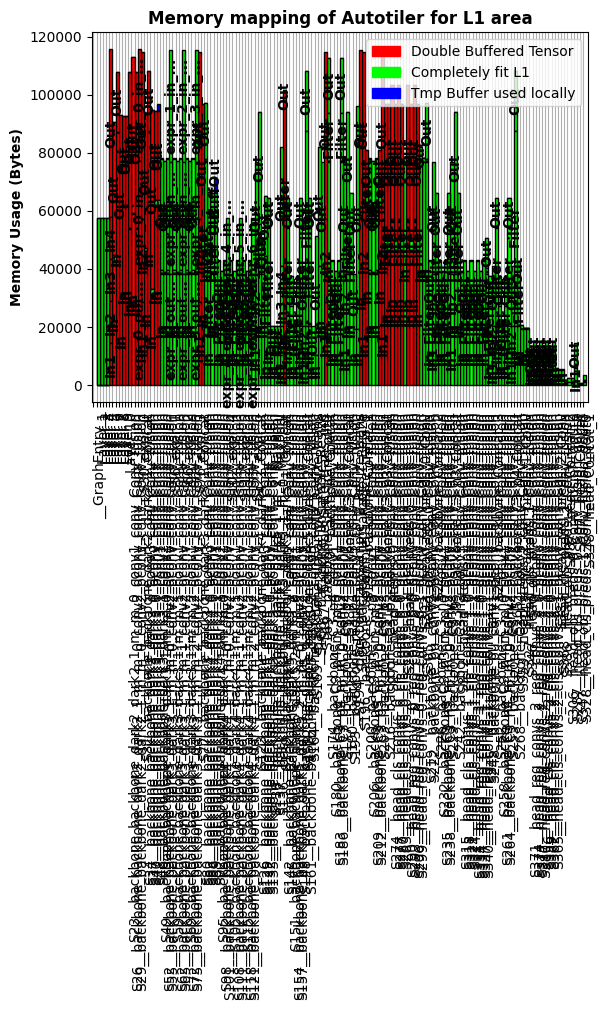

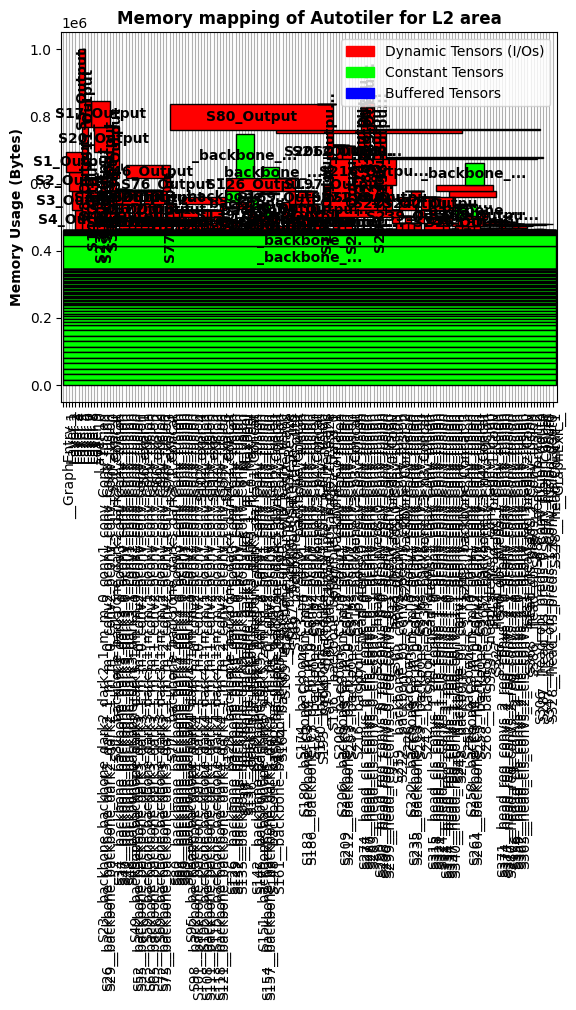

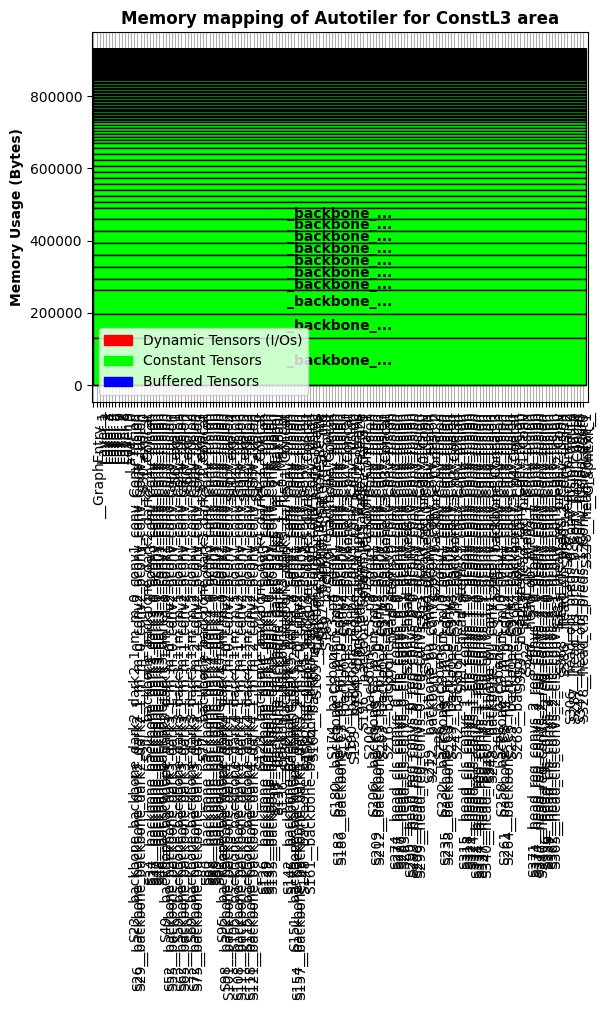

In [18]:
res.plot_memory_boxes()

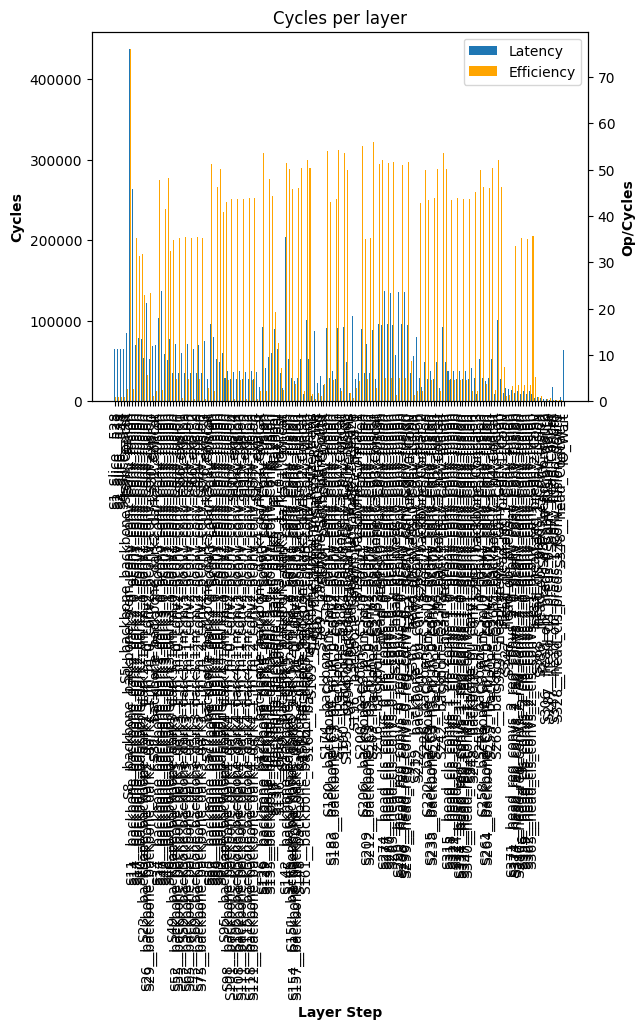

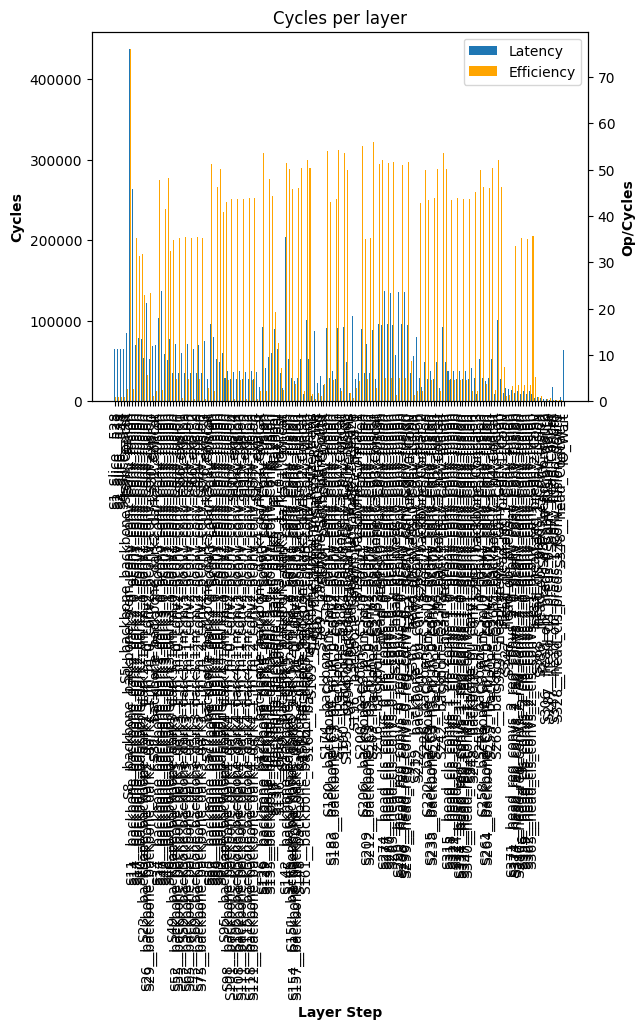

In [19]:
res.plot_performance()